# Reducing Variance With Bagging

## About This Project

In this project, you will reduce variance by implementing bootstrap aggregating (bagging) for regression trees.

### Evaluation

**This project must be successfully completed and submitted in order to receive credit for this course. Your score on this project will be included in your final grade calculation.**
    
You are expected to write code where you see `# YOUR CODE HERE` within the cells of this notebook. Not all cells will be graded; code input cells followed by cells marked with `# Auto-graded test cell` will be graded. Upon submitting your work, the code you write at these designated positions will be assessed using an "auto-grader" that will run all test cells to assess your code. You will receive feedback from the auto-grader that will identify any errors in your code. Use this feedback to improve your code if you need to resubmit. Be sure not to change the names of any provided functions, classes, or variables within the existing code cells, as this will interfere with the auto-grader. Also, remember to execute all code cells sequentially, not just those you’ve edited, to ensure your code runs properly.
    
You can resubmit your work as many times as necessary before the submission deadline. If you experience difficulty or have questions about this exercise, use the Q&A discussion board to engage with your peers or seek assistance from the instructor.

Before starting your work, please review [eCornell's policy regarding plagiarism](https://s3.amazonaws.com/ecornell/global/eCornellPlagiarismPolicy.pdf) (the presentation of someone else's work as your own without source credit).

### Submit Code for Auto-Grader Feedback

Once you have completed your work on this notebook, you will submit your code for auto-grader review. Follow these steps:

1. **Save your notebook.**

2. **Mark as Completed** — In the blue menu bar along the top of this code exercise window, you’ll see a menu item called **Education**. In the **Education** menu, click **Mark as Completed** to submit your code for auto-grader/instructor review. This process will take a moment and a progress bar will show you the status of your submission.

3. **Review your results** — Once your work is marked as complete, the results of the auto-grader will automatically be presented in a new tab within the code exercise window. You can click on the assessment name in this feedback window to see more details regarding specific feedback/errors in your code submission.

4. **Repeat, if necessary** — The Jupyter notebook will always remain accessible in the first tabbed window of the exercise. To reattempt the work, you will first need to click **Mark as Uncompleted** in the **Education** menu and then proceed to make edits to the notebook. Once you are ready to resubmit, follow steps one through three. You can repeat this procedure as many times as necessary.

You can also download a copy of this notebook in multiple formats using the **Save and Export Notebook As** option in the **File** menu above.

### Getting Started

Before you get started, let's import a few packages that you will need.

In [1]:
import numpy as np
from numpy.matlib import repmat
from scipy.io import loadmat
import time

# Interactive plots
%matplotlib ipympl
import matplotlib.pyplot as plt

import sys
sys.path.append("/home/codio/workspace/.modules")
from helper import *

print("Python version:", sys.version.split(" ")[0])

Python version: 3.12.5


In this project, we will work with an artificial 2D spiral dataset of size 150 (for visualization), and a high dimensional dataset [ION](https://archive.ics.uci.edu/ml/datasets/Ionosphere) (for a binary test classification problem).

In [2]:
xTrSpiral, yTrSpiral, xTeSpiral, yTeSpiral = spiraldata(150)
xTrIon, yTrIon, xTeIon, yTeIon = iondata()

You will use the regression tree from a previous project. As a reminder, the code in the next cell shows you how to train and evaluate a decision tree. Note that the first line creates a regression tree with no restriction on its depth and weights for each training example to be `1`. If you want to create a tree with a `max_depth` of `k`, then you would call `RegressionTree(depth=k)`.

In [3]:
# Create regression tree
tree = RegressionTree(depth=np.inf)

# Fit/train regression tree on spiral training dataset
tree.fit(xTrSpiral, yTrSpiral)

# Use the trained regression tree to predict scores
train_score = tree.predict(xTrSpiral)
test_score = tree.predict(xTeSpiral)

# Use the trained regression tree to make a +1/-1 prediction
train_pred = np.sign(train_score)
test_pred = np.sign(test_score)

# Calculate training and test error
train_err = np.mean(train_pred != yTrSpiral)
test_err = np.mean(test_pred != yTeSpiral)
print(f"Training Error: {100 * train_err:.2f}%")
print(f"Test Error: {100 * test_err:.2f}%")

Training Error: 0.00%
Test Error: 5.33%


The following code defines a function `visclassifier`, which plots the decision boundary of a classifier in two dimensions. Execute the following code to see what the decision boundary of your tree looks like on the spiral data set.

Training Error: 0.00%
Test Error: 5.33% (test points not shown in figure below)


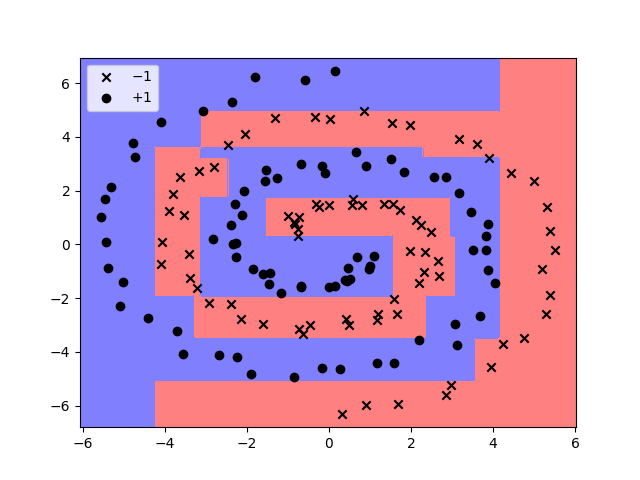

In [4]:
def visclassifier(fun, xTr, yTr):
    """
    Visualize a classifier and its decision boundary.
    Define the symbols and colors we'll use in the plots later.
    """
    yTr = np.array(yTr).flatten()

    # Get the unique values from labels array
    classvals = np.unique(yTr)

    # Return 300 evenly spaced numbers over this interval
    res = 300
    xrange = np.linspace(min(xTr[:, 0]) - 0.5, max(xTr[:, 0]) + 0.5, res)
    yrange = np.linspace(min(xTr[:, 1]) - 0.5, max(xTr[:, 1]) + 0.5, res)

    # Repeat this matrix 300 times for both axes
    pixelX = repmat(xrange, res, 1)
    pixelY = repmat(yrange, res, 1).T

    # Use the function (fun) to test all points on the grid
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    testpreds = fun(xTe)

    # Reshape it back together to make our grid
    Z = testpreds.reshape(res, res)
    Z[0, 0] = 1  # Optional: scale the colors correctly

    plt.figure()

    # Plot configuration
    labels = ["$-1$", "$+1$"]                  # Labels for training data
    symbols = ["x", "o"]                       # "x" for -1 and "o" for +1
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1 and blue for +1

    # Fill in the contours for these predictions
    plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)

    # Plot training data: "x" for -1 and "o" for +1
    for idx, c in enumerate(classvals):
        plt.scatter(
            xTr[yTr == c, 0],     # x-coordinate of training point
            xTr[yTr == c, 1],     # y-coordinate of training point
            label=labels[idx],    # Label of training point (-1 or +1)
            marker=symbols[idx],  # Marker of training point ("x" or "o")
            color="black",
        )

    plt.legend(loc="upper left")
    plt.axis("tight")
    plt.show()


# Compute tree on training data
tree = RegressionTree(depth=np.inf)
tree.fit(xTrSpiral, yTrSpiral)

# Determine training error and test error
train_err = np.mean(np.sign(tree.predict(xTrSpiral)) != yTrSpiral)
test_err = np.mean(np.sign(tree.predict(xTeSpiral)) != yTeSpiral)
print(f"Training Error: {100 * train_err:.2f}%")
print(f"Test Error: {100 * test_err:.2f}% (test points not shown in figure below)")

# Visualize classifier and decision boundary
visclassifier(lambda X: tree.predict(X), xTrSpiral, yTrSpiral)

## Bagging in Action

### Part One: Implement Bagging [Graded]

CART trees are known to be high variance classifiers if trained to full depth. Equivalently, CART trees of full depth easily overfit to the training set, which prevent the trees from performing well on new unseen data. An effective way to prevent overfitting is to use **bagging** (short for **b**ootstrap **agg**regat**ing**). Implement the function **`forest`**, which builds a forest of `m` regression trees of `depth=maxdepth`. Each tree should be built using training data drawn by randomly sampling `n` examples from the training data with replacement, where `n` is the number of points in `xTr`.

We are going to keep it simple and **not** randomly subsample a small set of features to split on. Therefore, all trees will be constructed with a simple call to `RegressionTree(depth=maxdepth)`. The function should output the list of trees.

**NOTE:** [You may find `np.random.choice(a, b, replace=True)` useful.](https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html) It samples `b` numbers from `[0, ..., a-1]` with replacement.

In [13]:
def forest(xTr, yTr, m, maxdepth=np.inf):
    """
    Creates a forest of m trees, each of depth=maxdepth.

    Input:
        xTr: nxd matrix of data points
        yTr: n-dimensional vector of labels
        m: Number of trees in the forest
        maxdepth: Maximum depth of each tree

    Output:
        trees: List of decision trees of length m
    """
    n, _ = xTr.shape
    trees = []

    # YOUR CODE HERE
    for i in range(m):
        index = np.random.choice(n, n, replace=True)
        x_bootstrap = xTr[index]
        y_bootstrap = yTr[index]
        tree = RegressionTree(depth=maxdepth)
        tree.fit(x_bootstrap, y_bootstrap)
        trees.append(tree)
    # END OF YOUR CODE

    return trees

Run the next cell to check your implementation of `forest`.

In [14]:
def forest_test1():
    """
    Check that forest has the correct number of trees
    """
    m = 20
    x = np.arange(100).reshape((100, 1))
    y = np.arange(100)
    trees = forest(x, y, m)
    return len(trees) == m


def forest_test2():
    """
    Check that all trees have correct max depth
    """
    m = 20
    x = np.arange(100).reshape((100, 1))
    y = np.arange(100)
    max_depth = 4
    trees = forest(x, y, m, max_depth)
    depths_forest = np.array([tree.depth for tree in trees])
    return np.all(depths_forest == max_depth)


def forest_test3():
    """
    Check that about 63% of data is represented in each random sample
    """
    s = set()  # Initialize a set for storing predictions

    def DFScollect(tree):
        """
        Depth-first search that collects all predictions in tree
        """
        if tree.left is None and tree.right is None:
            s.add(tree.prediction)
        else:
            DFScollect(tree.right)
            DFScollect(tree.left)

    m = 200
    x = np.arange(100).reshape((100, 1))
    y = np.arange(100)
    trees = forest(x, y, m)

    lens = np.zeros(m)

    for i in range(m):
        s.clear()
        DFScollect(trees[i].root)
        lens[i] = len(s)

    return abs(np.mean(lens) - 100 * (1 - 1 / np.exp(1))) < 2


runtest(forest_test1, "forest_test1")
runtest(forest_test2, "forest_test2")
runtest(forest_test3, "forest_test3")

Running Test: forest_test1 ... ✔ Passed!
Running Test: forest_test2 ... ✔ Passed!
Running Test: forest_test3 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (forest_test1)

In [ ]:
# Auto-graded test cell worth one point (forest_test2)

In [ ]:
# Auto-graded test cell worth one point (forest_test3)

### Part Two: Implement `evalforest` [Graded]

Now implement the function **`evalforest`**, which should take as input a set of $m$ trees and a set of $n$ test inputs and return the **average** prediction of all the trees.

Note that for bagging, we take the average over all trees weighted equally. In a later project, you will implement a different version of this function that assigns different weights to predictions of different trees.

In [15]:
def evalforest(trees, X):
    """
    Evaluates X using trees.

    Input:
        trees: List of length m of RegressionTree decision trees
        X: nxd matrix of data points

    Output:
        pred: n-dimensional vector of predictions
    """
    m = len(trees)
    n, _ = X.shape
    pred = np.zeros(n)

    # YOUR CODE HERE
    for tree in trees:
        pred += tree.predict(X)

    pred /= m
        
    # END OF YOUR CODE

    return pred

Run the next cell to check your implementation of `evalforest`.

In [16]:
def evalforest_test1():
    """
    Check that predictions array has correct shape
    """
    m = 200
    x = np.arange(100).reshape((100, 1))
    y = np.arange(100)
    trees = forest(x, y, m)
    preds = evalforest(trees, x)
    return preds.shape == y.shape


def evalforest_test2():
    """
    Check that predictions are correct
    """
    m = 200
    x = np.ones(10).reshape((10, 1))
    y = np.ones(10)
    max_depth = 0

    # Create a forest with trees depth 0.
    # Since the data are all ones, each tree will return 1 as prediction.
    trees = forest(x, y, m, 0)
    pred = evalforest(trees, np.ones((1, 1)))[0]

    # The prediction should be equal to the sum of weights
    return np.isclose(pred, 1)


def bagging_test1():
    """
    Check that bagging yields an improvement (or doesn't get much worse)
    """
    np.random.seed(1)  # Seed the random number generator for consistency
    xTr = np.random.rand(500, 3) - 0.5
    yTr = np.sign(xTr[:, 0] * xTr[:, 1] * xTr[:, 2])  # XOR Classification
    xTe = np.random.rand(50, 3) - 0.5
    yTe = np.sign(xTe[:, 0] * xTe[:, 1] * xTe[:, 2])

    tree = RegressionTree(depth=5)
    tree.fit(xTr, yTr)
    oneacc = np.sum(np.sign(tree.predict(xTe)) == yTe)

    m = 50  # Number of trees
    trees = forest(xTr, yTr, m, maxdepth=5)
    multiacc = np.sum(np.sign(evalforest(trees, xTe)) == yTe)

    return multiacc * 1.1 >= oneacc


def bagging_test2():
    """
    Another check that bagging yields an improvement (or doesn't get much worse)
    """
    np.random.seed(2)  # Seed the random number generator for consistency
    xTr = (np.random.rand(500, 3) - 0.5) * 4
    yTr = xTr[:, 0] * xTr[:, 1] * xTr[:, 2]  # XOR Regression
    xTe = (np.random.rand(50, 3) - 0.5) * 4
    yTe = xTe[:, 0] * xTe[:, 1] * xTe[:, 2]

    tree = RegressionTree(depth=3)
    tree.fit(xTr, yTr)
    oneerr = np.sum(np.sqrt((tree.predict(xTe) - yTe) ** 2))

    m = 50  # Number of trees
    trees = forest(xTr, yTr, m, maxdepth=3)
    multierr = np.sum(np.sqrt((evalforest(trees, xTe) - yTe) ** 2))

    return multierr <= oneerr * 1.5


runtest(evalforest_test1, "evalforest_test1")
runtest(evalforest_test2, "evalforest_test2")
runtest(bagging_test1, "bagging_test1")
runtest(bagging_test2, "bagging_test2")

Running Test: evalforest_test1 ... ✔ Passed!
Running Test: evalforest_test2 ... ✔ Passed!
Running Test: bagging_test1 ... ✔ Passed!
Running Test: bagging_test2 ... ✔ Passed!


Skip over the auto-graded test cells below (see [Evaluation](#Evaluation) for details).

In [ ]:
# Auto-graded test cell worth one point (evalforest_test1)

In [ ]:
# Auto-graded test cell worth one point (evalforest_test2)

In [ ]:
# Auto-graded test cell worth one point (bagging_test1)

In [ ]:
# Auto-graded test cell worth one point (bagging_test2)

### Visualize the Decision Boundary

The following script visualizes the decision boundary of an ensemble of decision tree. You might observe that the decision boundary is less rigid with an ensemble of 50 trees than with just 1 CART tree. This is to be expected as a forest is just an ensemble of CART trees and averages the predictions. Consequently, the test error should also be less with the the ensemble than with just 1 CART tree.

Training Error: 0.00%
Test Error: 3.33% (test points not shown in figure below)


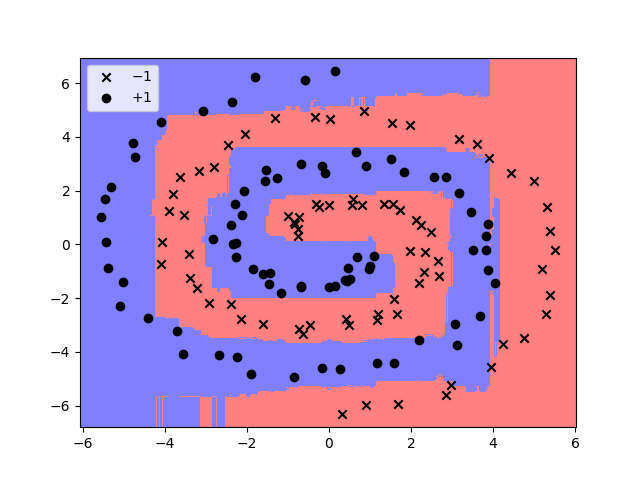

In [17]:
# Compute tree on training data
trees = forest(xTrSpiral, yTrSpiral, 50)

# Determine training and test error
train_error = np.mean(np.sign(evalforest(trees, xTrSpiral)) != yTrSpiral)
test_error = np.mean(np.sign(evalforest(trees, xTeSpiral)) != yTeSpiral)
print(f"Training Error: {100 * train_error:.2f}%")
print(f"Test Error: {100 * test_error:.2f}% (test points not shown in figure below)")

# Visualize classifier and decision boundary
visclassifier(lambda X: evalforest(trees, X), xTrSpiral, yTrSpiral)

### Evaluate Training and Test Error

The following script evaluates the training and testing error of an ensemble of decision trees as we vary the number of trees.

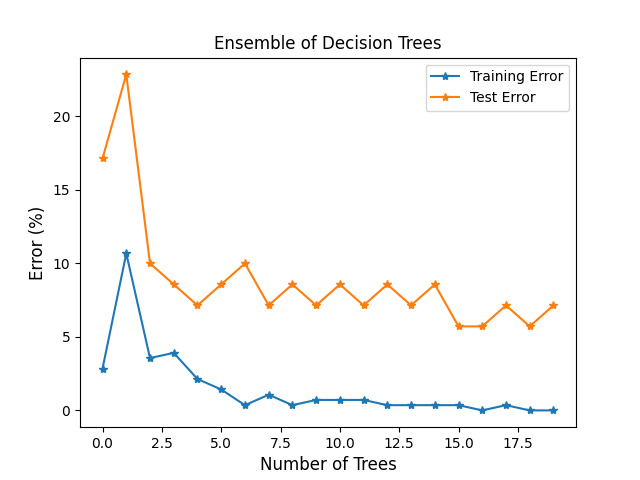

In [19]:
# Create forest with max number of trees
M = 20  # Max number of trees
alltrees = forest(xTrIon, yTrIon, M)

# Calculate training and test error
err_trB = []
err_teB = []
for i in range(M):
    trees = alltrees[: i + 1]
    trErr = np.mean(np.sign(evalforest(trees, xTrIon)) != yTrIon)
    teErr = np.mean(np.sign(evalforest(trees, xTeIon)) != yTeIon)
    err_trB.append(100 * trErr)  # Percentage training error
    err_teB.append(100 * teErr)  # Percentage test error

# Plot training error and test error
plt.figure()
(line_tr,) = plt.plot(range(M), err_trB, "-*", label="Training Error")
(line_te,) = plt.plot(range(M), err_teB, "-*", label="Test Error")
plt.title("Ensemble of Decision Trees")
plt.legend(handles=[line_tr, line_te])
plt.xlabel("Number of Trees", fontsize=12)
plt.ylabel("Error (%)", fontsize=12)
plt.show()

### 1D Interactive Demo

The next interactive demo shows a 1-dimensional curve fitted with ensembles of decision trees. We sample 100 training data points from the curve with additive noise. Note how the predicted curve becomes increasingly smooth as you add trees &mdash; adding trees should thus decrease training and testing error. The testing error may be a little higher than the training error, but there is no large gap as ensembles are quite good at avoiding overfitting. 

Please keep in mind:
1. You must run (or rerun) this cell before interacting with the plot.
2. You can either click to add one tree or shift+click to add 10 trees.


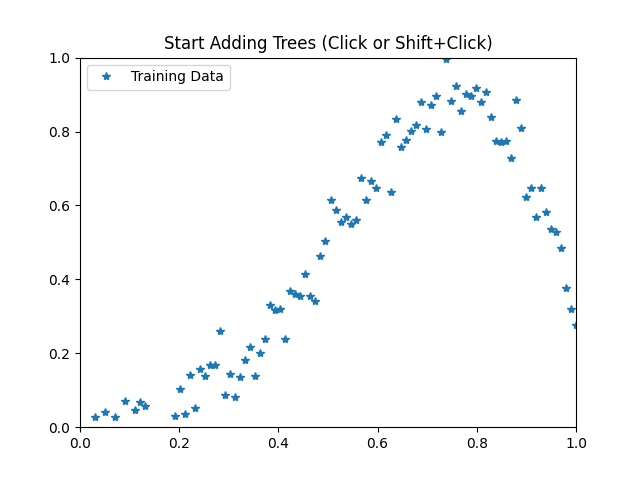

In [20]:
def onclick_forest(event):
    """
    Visualize forest by adding more trees
    """
    global xTrain, yTrain, M, Q, trees, weights

    if event.key == "shift":
        Q += 10
    else:
        Q += 1

    # Minimum between number of trees added (Q) and max number of trees (M)
    Q = min(Q, M)

    # Make predictions on training and test data
    pTrain = evalforest(trees[:Q], xTrain)
    pTest = evalforest(trees[:Q], xTest)

    # Plot configuration settings
    plt.cla()         # Clear axes
    plt.xlim((0, 1))  # x-axis limits
    plt.ylim((0, 1))  # y-axis limits

    plt.plot(xTrain[:, 0], yTrain, "*")  # Blue stars for training data
    plt.plot(xTest[:, 0], yTest, "k-.")  # Black dashed-dotted line for test data
    plt.plot(xTest[:, 0], pTest, "r-")   # Red dashed line for predictions on test data

    # Calculate mean squared error (MSE) for training and test data
    tr_MSE = np.sqrt(np.mean((pTrain - yTrain) ** 2))
    te_MSE = np.sqrt(np.mean((pTest - yTest) ** 2))

    if Q == 1:
        plt.title(f"({Q} Tree)  Training MSE: {tr_MSE:.4f}, Test MSE: {te_MSE:.4f}")
    else:
        plt.title(f"({Q} Trees)  Training MSE: {tr_MSE:.4f}, Test MSE: {te_MSE:.4f}")
    
    plt.legend(["Training Data", "Test Data", "Prediction"])
    plt.show()


# Generate training and test datasets
n = 100       # Number of training points
NOISE = 0.05  # Magnitude of noise
xTrain = np.array([np.linspace(0, 1, n), np.zeros(n)]).T
yTrain = 2 * np.sin(xTrain[:, 0] * 3) * (xTrain[:, 0] ** 2)
yTrain += np.random.randn(yTrain.size) * NOISE
ntest = 300   # Density of test points
xTest = np.array([np.linspace(0, 1, ntest), np.zeros(ntest)]).T
yTest = 2 * np.sin(xTest[:, 0] * 3) * (xTest[:, 0] ** 2)

# Hyperparameters (feel free to play with them)
M = 100         # Max number of trees for interactive demo
depth = np.inf  # Infinite depth
trees = forest(xTrain, yTrain, M, maxdepth=depth)
Q = 0           # Initial number of trees for interactive demo

# Interactive demo
print("Please keep in mind:")
print("1. You must run (or rerun) this cell before interacting with the plot.")
print("2. You can either click to add one tree or shift+click to add 10 trees.")
fig = plt.figure()
plt.title("Start Adding Trees (Click or Shift+Click)")
plt.plot(xTrain[:, 0], yTrain, "*")
plt.legend(["Training Data", "Test Data"])
plt.xlim(0, 1)
plt.ylim(0, 1)
cid = fig.canvas.mpl_connect("button_press_event", onclick_forest)

### 2D Interactive Demo

The following demo visualizes the bagged classifier. Add your own points directly on the graph with click and `shift`+click to see the prediction boundaries. There will be a delay between clicks as the new classifier is trained.

Please keep in mind:
1. You must run (or rerun) this cell right before interacting with the plot.
2. Start the interactive demo by clicking the grid to add a positive point.
3. Click to add a positive point or shift+click to add a negative point.
4. You may notice a slight delay when adding points to the visualization.


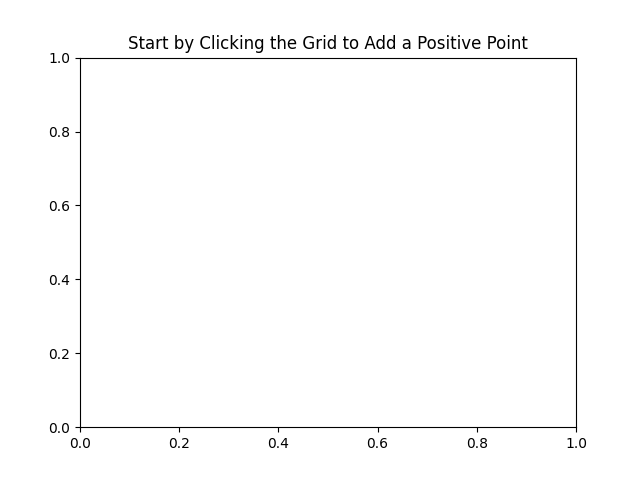

In [21]:
# Initialize empty array of width 2 to store training points
xTrain = np.empty((0, 2))

# Initialize empty array of width 1 to store training labels
yTrain = np.empty((0, 1))

# Number of trees
m = 5


def onclick_classifier(event):
    """
    Visualize classifier by adding new points
    """
    global xTrain, yTrain, m

    # Shift+click to add a negative point.
    # Click to add a positive point.
    if event.key == "shift":
        label = -1
    else:
        label = 1

    # Create position vector for new point
    pos = np.array([[event.xdata, event.ydata]])

    # Add new point to training data
    xTrain = np.concatenate((xTrain, pos), axis=0)
    yTrain = np.append(yTrain, label)

    # Get the class values from training labels
    classvals = np.unique(yTrain)
    
    # Return 300 evenly spaced numbers over interval [0, 1]
    res = 300
    xrange = np.linspace(0, 1, res)
    yrange = np.linspace(0, 1, res)

    # Repeat this matrix 300 times for both axes
    pixelX = repmat(xrange, res, 1)
    pixelY = repmat(yrange, res, 1).T

    # Get forest and function to evaluate forest
    trees = forest(xTrain, yTrain, M)
    fun = lambda X: evalforest(trees, X)

    # Test all of these points on the grid
    xTe = np.array([pixelX.flatten(), pixelY.flatten()]).T
    testpreds = fun(xTe)

    # Reshape test predictions to match the grid size
    Z = testpreds.reshape(res, res)
    Z[0, 0] = 1  # Optional: scale the colors correctly

    # Plot configuration
    plt.cla()                                  # Clear axes
    plt.xlim((0, 1))                           # x-axis limits
    plt.ylim((0, 1))                           # y-axis limits
    labels = ["$-1$", "$+1$"]                  # Labels for training points
    symbols = ["x", "o"]                       # "x" for -1 and "o" for +1 (training)
    mycolors = [[1, 0.5, 0.5], [0.5, 0.5, 1]]  # Red for -1 and blue for +1 (predictions)

    if len(classvals) == 1 and 1 in classvals:
        # Plot blue prediction contours because only +1 points have been added
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=[[0.5, 0.5, 1], [0.5, 0.5, 1]])
        
        # Plot points with "o" markers because only +1 points have been added
        for idx, c in enumerate(classvals):
            plt.scatter(
                xTrain[yTrain == c, 0],  # x-coordinate of training point
                xTrain[yTrain == c, 1],  # y-coordinate of training point
                label="$+1$",            # Label of training point
                marker="o",              # Marker of training point
                color="black",           # Color of training point
            )
    else:
        # Plot prediction contours: red for -1 and blue for +1
        plt.contourf(pixelX, pixelY, np.sign(Z), colors=mycolors)

        # Plot training data: "x" for -1 and "o" for +1
        for idx, c in enumerate(classvals):
            plt.scatter(
                xTrain[yTrain == c, 0],  # x-coordinate of training point
                xTrain[yTrain == c, 1],  # y-coordinate of training point
                label=labels[idx],       # Label of training point (-1 or +1)         
                marker=symbols[idx],     # Marker of training point ("x" or "o")
                color="black",           # Color of training point
            )

    plt.title("Click: Positive Point, Shift+Click: Negative Point")
    plt.legend(loc="upper left")
    plt.show()


# Interactive demo
print("Please keep in mind:")
print("1. You must run (or rerun) this cell right before interacting with the plot.")
print("2. Start the interactive demo by clicking the grid to add a positive point.")
print("3. Click to add a positive point or shift+click to add a negative point.")
print("4. You may notice a slight delay when adding points to the visualization.")
fig = plt.figure()
plt.title("Start by Clicking the Grid to Add a Positive Point")
plt.xlim(0, 1)
plt.ylim(0, 1)
cid = fig.canvas.mpl_connect("button_press_event", onclick_classifier)